# 5 - Figure 5: Experiment 5 (orthogonal responses)

Experiment 5 (`EX_11`) keeps Experiment 1b's binaural left/right judgement but collects it on the
**UP / DOWN** keys, with the key mapping reversed between the two halves of the experiment, so the
side of the sound and the position of the response key no longer share an axis.

| Panel | Content |
|---|---|
| **A** | left empty here — the task schematic is added in the manuscript |
| **B** | saccade count, sound-locked (all sounds) |
| **C** | P(Correct), sound-locked (all sounds; omission = error, as in Figure 4) |
| **D** | P(Correct Response), response-locked (responded sounds only) |

Line plots only, each axis the size of a Figure 2 line plot. Exp 5 gets its exclusions from
`src/exclusions.py` (reversed blocks, then E11004 and E11010).

**Per alignment:**

| | sound-locked (B, C) | response-locked (D) |
|---|---|---|
| sounds | all (`build_filter(data)`) | responded only — a sound with no response has no t = 0 |
| accuracy | `p_correct_response`, omission = error | `p_correct_response`, which equals `p_correct_choice` here |
| vs-baseline tests | pre-sound baseline, −500…0 ms from sound | the same sound-locked baseline, on the responded subset |
| grey dashed line + band | median RT (the response) and IQR | −median RT (sound onset) and −IQR |
| P(correct) y-range | pre-sound centre ± 25 % of the centre, as Figure 4 | fitted to the spread of the response-locked curves **and** amplitude × time matrix about the pre-sound centre (× `PCR_MARGIN_PAD`, clipped to [0, 1]) |

The response-locked heatmap matrices are computed only to set panel D's y-range (it is the range
the response-locked panels use wherever they are drawn with heatmaps); they are not plotted.

The saccade-count range is (−60, 30) instead of Figure 2's (−42, 42): Exp 5's incongruent dip
reaches about −50 % and would be clipped.

**Input**   `data_preprocessed/EX_11/long_format_ex11_all.csv`
**Output**  `summaries/plots/figure5.{png,pdf}`

**Caching — a routine run only plots.** `summaries/cache/figure5_curves/` holds the curves, RT
and P(correct) centres, keyed on the analysis parameters, the data file's size/mtime and the source
of `config.py`, `peri_sac.py` and `exclusions.py`, so it rebuilds itself after any of those change
(`FORCE_RECOMPUTE = True` forces it). `summaries/cache/figure5.pkl` holds the significance tests
and y-ranges and is **not** keyed: set `LOAD_CACHE = False` after re-preprocessing or changing a
statistics parameter.

In [1]:
%load_ext autoreload
%autoreload 2

import hashlib
import math
import os
import pickle
import sys
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D

sys.path.insert(0, 'src')

import config
import peri_sac
import exclusions
import src.analysis_heatmap as analysis_heatmap

importlib.reload(config)
importlib.reload(peri_sac)
importlib.reload(exclusions)
importlib.reload(analysis_heatmap)

from peri_sac import (
    calculate_running_window_metrics,
    plot_single_condition,
    test_pairwise_conditions,
    test_condition_vs_baseline,
    calculate_baseline_metrics_from_trials,
    apply_fdr_correction,
    plot_significance_bars,
    DEFAULT_METRICS,
    COLOR_PALETTES,
)
from config import EXPERIMENT_CONFIGS, build_filter, prepare_alternative_data, METRIC_COLUMN_MAP
from src.analysis_heatmap import prepare_amplitude_time_heatmap

%matplotlib inline
plt.rcParams['figure.dpi'] = 300
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

## Configuration

In [2]:
# ====================================================================
# EXPERIMENT
# ====================================================================

EXPERIMENT = 'EX_11'
NAME       = 'Exp 5'

def panel_title(alignment):
    return f'{NAME}. {alignment}-locked'

# ====================================================================
# TIME / WINDOW PARAMETERS
# ====================================================================

SOUND_REFERENCE    = 'time_from_sound_to_sacc_start'
RESPONSE_REFERENCE = 'time_from_RT_to_sacc_start'
BASELINE_REFERENCE = SOUND_REFERENCE      # the baseline is always pre-sound, sound-locked
BASELINE_RANGE     = (-500, 0)
WINDOW_SIZE        = 100
STEP_SIZE          = 25
MIN_CORRECTION_N   = 5

ALIGNMENTS = {
    'sound': {
        'reference':      SOUND_REFERENCE,
        'time_range':     (-500, 1000),      # as Figures 2 and 4
        'responded_only': False,             # all sounds
        'count_metric':   'saccade_count_normalized',
        'acc_metric':     'p_correct_response',
        'xlabel':         'Time from sound onset (ms)',
    },
    'response': {
        'reference':      RESPONSE_REFERENCE,
        'time_range':     (-1000, 500),      # same 1500 ms span as sound-locked
        'responded_only': True,              # a sound with no response has no t = 0
        'count_metric':   'saccade_count_normalized_spec',
        'acc_metric':     'p_correct_response',   # = p_correct_choice on this subset
        'xlabel':         'Time from response (ms)',
    },
}

# ====================================================================
# FIGURE PARAMETERS  (Figure 2's unless noted)
# ====================================================================

COUNT_YLIM   = (-60, 30)            # Figure 2's (-42, 42) clips Exp 5's dip
COUNT_YTICKS = [-50, -25, 0, 25]
YLABEL_D     = 'P(Correct Response)'

CELL_W_V2    = 8.5                  # Figure 2 per-panel size; its canvas = 2 x 2 of these
CELL_H_V2    = 4.1
LINE_W_RATIO = 2.5
HM_W_RATIO   = 1.3
CBAR_W_RATIO = 0.09
FONTSIZE     = 12

# The legend sits in panel D: its lower-right corner is empty, while the sound-locked
# incongruent dip fills every lower-left corner.
LEGEND_LOC   = 'lower right'
LEGEND_POS   = (1.015, -0.02)

# Gaps between line axes, in inches; each line axis keeps Figure 2's line-plot size exactly.
LINE_GAP_W_IN = 1.35
LINE_GAP_H_IN = 1.25

# Amplitude x time matrices, used only to set panel D's y-range
HM_AMPLITUDE_COL      = METRIC_COLUMN_MAP['amplitude']
HM_BINNING_METHOD     = 'quantile_presound'
HM_N_BINS             = 10
HM_PER_SUBJECT        = False
HM_PRESOUND_THRESHOLD = 0           # on the sound-locked column: bins stay pre-sound
HM_WINDOW_SIZE        = WINDOW_SIZE * 2
HM_STEP_SIZE          = STEP_SIZE * 2

PCR_SOUND_MARGIN = 0.25             # sound-locked band = centre +- 25 % of centre (Figure 4)
PCR_MARGIN_PAD   = 1.1              # response-locked band = spread x pad

OUTPUT_PATH = Path('summaries') / 'plots'
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)
CACHE_DIR = Path('summaries') / 'cache'
CACHE_DIR.mkdir(parents=True, exist_ok=True)
CURVE_CACHE_DIR = CACHE_DIR / 'figure5_curves'
FORCE_RECOMPUTE = False

## Curves (cached; the raw table loads only if needed)

In [3]:
CONDITIONS = [('consistent', True), ('inconsistent', False)]

_table = {}

def table():
    '''(data, {alignment: {'filter', 'filters'}}) - read from disk on first use only.'''
    if not _table:
        print('  loading the EX_11 table ...')
        data = config.load_experiment_data(EXPERIMENT)
        data, _ = exclusions.apply_exp5_exclusions(data)   # reversed blocks, then E11004 / E11010
        filt = {}
        for alignment, spec in ALIGNMENTS.items():
            base = build_filter(data, include_response=spec['responded_only'])
            if spec['responded_only']:
                base = base & (data['response_given'] == 1)
            filt[alignment] = {'filter': base,
                               'filters': {c: base & (data['consistent'] == v) for c, v in CONDITIONS}}
        _table['v'] = (data, filt)
    return _table['v']


def curve_key():
    data_file = Path(f'data_preprocessed/{EXPERIMENT}') / EXPERIMENT_CONFIGS[EXPERIMENT]['data_file']
    st = data_file.stat()
    h = hashlib.sha256(repr((EXPERIMENT, ALIGNMENTS, BASELINE_REFERENCE, BASELINE_RANGE, WINDOW_SIZE,
                             STEP_SIZE, MIN_CORRECTION_N, HM_WINDOW_SIZE, HM_STEP_SIZE,
                             str(data_file), st.st_size, st.st_mtime_ns)).encode())
    for m in ('src/config.py', 'src/peri_sac.py', 'src/exclusions.py'):
        h.update(Path(m).read_bytes())
    return h.hexdigest()[:16]


def compute_curves():
    data, filt = table()
    sdt_column = EXPERIMENT_CONFIGS[EXPERIMENT]['sdt_column']
    out = {'aligned': {}, 'pcr_centre': {}}
    for alignment, spec in ALIGNMENTS.items():
        out['aligned'][alignment] = {
            c: calculate_running_window_metrics(
                data, filt[alignment]['filters'][c], spec['reference'],
                window_size=WINDOW_SIZE, step_size=STEP_SIZE, time_range=spec['time_range'],
                # baseline_range is what makes the _spec count appear; its baseline is the
                # sound-locked pre-sound window on this same subset.
                baseline_range=BASELINE_RANGE,
                sdt_column=sdt_column, sdt_min_correction_n=MIN_CORRECTION_N)
            for c, _ in CONDITIONS
        }
        # P(correct) centre: pre-sound P(correct), sound-locked, on this alignment's subset
        bl = calculate_running_window_metrics(
            data, filt[alignment]['filter'], BASELINE_REFERENCE,
            window_size=HM_WINDOW_SIZE, step_size=HM_STEP_SIZE,
            time_range=BASELINE_RANGE if alignment == 'response' else spec['time_range'],
            baseline_range=BASELINE_RANGE)
        out['pcr_centre'][alignment] = float(
            bl.loc[bl['window_center'].between(*BASELINE_RANGE), spec['acc_metric']].dropna().mean())
    # Median RT and IQR (responded rows, rt > 0)
    responded = build_filter(data, include_response=True) & (data['response_given'] == 1) & (data['rt'] > 0)
    rt = data.loc[responded, 'rt']
    out['rt'] = (float(rt.median()), float(rt.quantile(0.25)), float(rt.quantile(0.75)))
    out['n_subjects'] = int(data.loc[responded, 'id_subject'].nunique())
    return out


CURVE_CACHE_DIR.mkdir(parents=True, exist_ok=True)
path = CURVE_CACHE_DIR / f'{EXPERIMENT}_{curve_key()}.pkl'
if path.exists() and not FORCE_RECOMPUTE:
    with open(path, 'rb') as f:
        curves = pickle.load(f)
else:
    print(f'=== {EXPERIMENT}: computing curves ===')
    curves = compute_curves()
    for stale in CURVE_CACHE_DIR.glob(f'{EXPERIMENT}_*.pkl'):
        stale.unlink()
    with open(path, 'wb') as f:
        pickle.dump(curves, f, protocol=pickle.HIGHEST_PROTOCOL)

print(f"{EXPERIMENT}: n = {curves['n_subjects']}  |  median RT = {curves['rt'][0]:.0f} ms  "
      f"[Q1 = {curves['rt'][1]:.0f}, Q3 = {curves['rt'][2]:.0f}]")

=== EX_11: computing curves ===
  loading the EX_11 table ...
Loading: data_preprocessed/EX_11\long_format_ex11_all.csv


  Raw data loaded: 249,826 rows
  Unique subjects: 55


  Data prepared using closest sound approach


Exp 5: reversed blocks dropped: 3 of 550 (E11033 upR block 2, E11033 upR block 3, E11047 upR block 4)
Exp 5: participants excluded: E11004, E11010 -> 53 analysed


EX_11: n = 53  |  median RT = 758 ms  [Q1 = 605, Q3 = 972]


In [4]:
def _make_3_ticks(vmin, vmax):
    vmid = (vmin + vmax) / 2
    span = abs(vmax - vmin)
    if span == 0:
        return [vmin]
    if max(abs(vmin), abs(vmax)) <= 1:
        lo  = math.ceil(vmin * 100) / 100
        hi  = math.floor(vmax * 100) / 100
        mid = round(vmid, 2)
    else:
        if span >= 50:
            scale = 10
        elif span >= 10:
            scale = 5
        elif span >= 1:
            scale = 1
        elif span >= 0.1:
            scale = 0.1
        else:
            scale = 0.05
        lo  = math.ceil(vmin / scale) * scale
        hi  = math.floor(vmax / scale) * scale
        mid = round(vmid / scale) * scale
    return sorted({lo, mid, hi})


def ref_lines(alignment):
    '''Grey line + band marking the *other* event: the response (+RT) when sound-locked,
    sound onset (-RT) when response-locked.'''
    median, q1, q3 = curves['rt']
    if alignment == 'sound':
        return median, q1, q3
    return -median, -q3, -q1


def run_significance(alignment, metric):
    '''Congruent vs incongruent and each vs the sound-locked pre-sound baseline, FDR-corrected
    as one family (one metric x all windows), as in Figures 2 and 4.'''
    data, filt = table()
    res = curves['aligned'][alignment]
    cols = ['id_subject', 'window_center', metric]
    merged = (res['consistent'][cols].rename(columns={metric: f'{metric}_cond0'})
              .merge(res['inconsistent'][cols].rename(columns={metric: f'{metric}_cond1'}),
                     on=['id_subject', 'window_center'], how='outer'))
    centres = merged['window_center'].dropna().unique()

    sig = {f'{metric}_cond0_vs_cond1': []}
    for wc in centres:
        r = test_pairwise_conditions(merged[merged['window_center'] == wc], metric, '_cond0', '_cond1')
        r['window_center'] = wc
        sig[f'{metric}_cond0_vs_cond1'].append(r)

    for ci, (cond, _) in enumerate(CONDITIONS):
        bd = calculate_baseline_metrics_from_trials(
            data[filt[alignment]['filters'][cond]], BASELINE_RANGE, BASELINE_REFERENCE)
        key = f'{metric}_cond{ci}_vs_baseline'
        sig[key] = []
        for wc in centres:
            r = test_condition_vs_baseline(
                merged[merged['window_center'] == wc], bd, metric, metric_suffix=f'_cond{ci}',
                baseline_range=BASELINE_RANGE, window_size=WINDOW_SIZE)
            r['window_center'] = wc
            sig[key].append(r)
    return apply_fdr_correction(sig)


print('helpers ready')

helpers ready


## Statistics and y-ranges (cached)

In [5]:
# ====================================================================
# CACHE - significance (count + accuracy, both alignments) and P(correct) y-ranges
# ====================================================================
# Recompute (LOAD_CACHE = False) after re-preprocessing or changing a statistics parameter;
# display-only changes never need it.
# ====================================================================

LOAD_CACHE = True
CACHE_FILE = CACHE_DIR / 'figure5.pkl'

cache = {'sig': {}, 'acc_band': {}}
if LOAD_CACHE and CACHE_FILE.exists():
    with open(CACHE_FILE, 'rb') as _f:
        cache = pickle.load(_f)
    print(f'Loaded cache: {CACHE_FILE}')

_missing = [a for a in ALIGNMENTS if a not in cache['acc_band']]
for alignment in _missing:
    spec = ALIGNMENTS[alignment]
    data, filt = table()
    for metric in (spec['count_metric'], spec['acc_metric']):
        cache['sig'][(alignment, metric)] = run_significance(alignment, metric)
    print(f'{alignment}: significance done')

    acc = spec['acc_metric']
    vc = curves['pcr_centre'][alignment]
    if alignment == 'sound':
        # As Figure 4: centre +- 25 % of centre
        vmin, vmax = vc * (1 - PCR_SOUND_MARGIN), vc * (1 + PCR_SOUND_MARGIN)
    else:
        # The spread of the curves and of the amplitude x time matrix about the centre
        dev = 0.0
        for cond, consistency in CONDITIONS:
            print(f'  amplitude x time matrix, {alignment} / {cond} ...', end=' ', flush=True)
            mt = prepare_amplitude_time_heatmap(
                data=data, analysis_filter=filt[alignment]['filter'], amplitude_col=HM_AMPLITUDE_COL,
                time_reference=spec['reference'], time_range=spec['time_range'],
                baseline_range=BASELINE_RANGE, consistency=consistency,
                window_size=HM_WINDOW_SIZE, step_size=HM_STEP_SIZE, binning_method=HM_BINNING_METHOD,
                n_bins=HM_N_BINS, per_subject=HM_PER_SUBJECT, presound_threshold=HM_PRESOUND_THRESHOLD,
                metric=acc, vlim=(0.0, 1.0), vcenter=vc)['matrix']
            print('done')
            mt = mt[np.isfinite(mt)]
            if mt.size:
                dev = max(dev, float(np.abs(mt - vc).max()))
            g = curves['aligned'][alignment][cond].groupby('window_center')[acc].mean().dropna()
            if len(g):
                dev = max(dev, float((g - vc).abs().max()))
        dev = max(dev * PCR_MARGIN_PAD, 1e-3)
        vmin, vmax = max(0.0, vc - dev), min(1.0, vc + dev)
    cache['acc_band'][alignment] = (vmin, vmax, vc)

if _missing:
    with open(CACHE_FILE, 'wb') as _f:
        pickle.dump(cache, _f)
    print(f'Saved cache: {CACHE_FILE}')
for a, (lo, hi, vc) in cache['acc_band'].items():
    print(f'{a}: P(correct) y-range ({lo:.3f}, {hi:.3f}), pre-sound centre {vc:.3f}')

sound: significance done


response: significance done
  amplitude x time matrix, response / consistent ... 

Calculating quantiles based on 45461 pre-sound observations
  (out of 87771 total valid observations)
Bin edges (from pre-sound data): [-inf 0.75 1.26 1.83 2.57 3.51 4.59 5.83 7.48 9.99  inf]


done
  amplitude x time matrix, response / inconsistent ... 

Calculating quantiles based on 45321 pre-sound observations
  (out of 87330 total valid observations)
Bin edges (from pre-sound data): [-inf 0.76 1.25 1.8  2.53 3.46 4.56 5.82 7.46 9.98  inf]


done
Saved cache: summaries\cache\figure5.pkl
sound: P(correct) y-range (0.499, 0.831), pre-sound centre 0.665
response: P(correct) y-range (0.652, 0.940), pre-sound centre 0.796


## Drawing helpers

In [6]:
colors          = COLOR_PALETTES[2]   # [congruent, incongruent]
condition_names = ('Congruent', 'Incongruent')
FIG2_WIDTH_IN   = 14.41                # Figure 2 PNG width (tight crop at 300 dpi)


def _arial(ax):
    for lbl in ax.get_xticklabels() + ax.get_yticklabels():
        lbl.set_fontfamily('Arial')


def draw_line(ax, alignment, kind, title=None, panel_label=None, legend=False, ylabel=None):
    '''Figure 2's line plot for one alignment and kind ('count' or 'acc').'''
    spec   = ALIGNMENTS[alignment]
    metric = spec['count_metric'] if kind == 'count' else spec['acc_metric']
    res    = curves['aligned'][alignment]
    sig    = cache['sig'][(alignment, metric)]

    for ci, (cond, _) in enumerate(CONDITIONS):
        plot_single_condition(ax, res[cond], metric, colors[ci], condition_names[ci])

    ax.axvline(0, color='black', linestyle='--', linewidth=2, alpha=0.5)
    line, q_lo, q_hi = ref_lines(alignment)
    ax.axvline(line, color='gray', linestyle='--', linewidth=2, alpha=0.5)
    ax.axvspan(q_lo, q_hi, color='lightgray', alpha=0.2, zorder=0)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(False)
    ax.tick_params(axis='both', labelsize=FONTSIZE, labelbottom=True)
    if title:
        ax.set_title(title, fontsize=FONTSIZE + 1, fontweight='bold', fontfamily='Arial', y=1.02)
    # Response-locked count: same label as sound-locked (both are % change from pre-sound)
    ylabel_metric = 'saccade_count_normalized' if kind == 'count' else metric
    ax.set_ylabel(ylabel or DEFAULT_METRICS.get(ylabel_metric, {}).get('label', metric),
                  fontsize=FONTSIZE, fontfamily='Arial')
    ax.set_xlabel(spec['xlabel'], fontsize=FONTSIZE, fontfamily='Arial')

    if kind == 'count':
        ax.set_ylim(COUNT_YLIM)
        ref_y = 0.0
    else:
        vmin, vmax, vc = cache['acc_band'][alignment]
        ax.set_ylim(vmin, vmax)
        ref_y = vc if alignment == 'response' else (vmin + vmax) / 2   # mid-axis = centre
    ax.axhline(ref_y, color='grey', linestyle=':', linewidth=0.8, alpha=0.8, zorder=1)

    plot_significance_bars(ax, sig[f'{metric}_cond0_vs_cond1'], 0.05, 'grey', linewidth=3)
    for ci in range(2):
        key = f'{metric}_cond{ci}_vs_baseline'
        if key in sig:
            plot_significance_bars(ax, sig[key], 0.05 + 0.025 + 0.05 + ci * 0.025, colors[ci], linewidth=3)

    if kind == 'count' and COUNT_YTICKS is not None:
        ax.set_yticks(COUNT_YTICKS)
    else:
        ax.set_yticks(_make_3_ticks(*ax.get_ylim()))
    _arial(ax)

    if panel_label:
        ax.text(-0.2, 1.12, panel_label, transform=ax.transAxes, fontsize=FONTSIZE + 6,
                fontweight='bold', fontfamily='Arial', va='top', ha='left')
    if legend:
        handles = [Line2D([0], [0], color=colors[i], linewidth=3, label=condition_names[i]) for i in range(2)]
        ax.legend(handles=handles, loc=LEGEND_LOC, bbox_to_anchor=LEGEND_POS,
                  prop={'family': 'Arial', 'size': FONTSIZE}, frameon=True)


def empty_axes(ax, panel_label):
    '''An empty panel that carries only its letter, where a drawn panel's letter would be.'''
    ax.axis('off')
    ax.text(-0.2, 1.12, panel_label, transform=ax.transAxes, fontsize=FONTSIZE + 6,
            fontweight='bold', fontfamily='Arial', va='top', ha='left')


def fig2_line_axes_size():
    '''Width and height (in) of a line plot inside a Figure 2 panel.'''
    fig = plt.figure(figsize=(CELL_W_V2 * 2, CELL_H_V2 * 2))
    gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.40, wspace=0.25)
    pg = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs[0, 0],
                                          width_ratios=[LINE_W_RATIO + HM_W_RATIO, CBAR_W_RATIO], wspace=0.06)
    pl = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=pg[0, 0], width_ratios=[LINE_W_RATIO, HM_W_RATIO],
                                          height_ratios=[1, 1], wspace=0.22, hspace=0.12)
    b = pl[0:2, 0].get_position(fig)
    w, h = b.width * fig.get_figwidth(), b.height * fig.get_figheight()
    plt.close(fig)
    return w, h


def line_grid(n_rows, n_cols):
    '''Axes of Figure 2's line-plot size on a grid with fixed inch gaps.'''
    aw, ah = fig2_line_axes_size()
    margin = 1.0
    W = 2 * margin + n_cols * aw + (n_cols - 1) * LINE_GAP_W_IN
    H = 2 * margin + n_rows * ah + (n_rows - 1) * LINE_GAP_H_IN
    fig = plt.figure(figsize=(W, H))
    axes = [[fig.add_axes([(margin + c * (aw + LINE_GAP_W_IN)) / W,
                           (H - margin - (r + 1) * ah - r * LINE_GAP_H_IN) / H,
                           aw / W, ah / H])
             for c in range(n_cols)] for r in range(n_rows)]
    return fig, axes


def save(fig, name):
    png = OUTPUT_PATH / f'{name}.png'
    fig.savefig(png, dpi=300, bbox_inches='tight')
    fig.savefig(OUTPUT_PATH / f'{name}.pdf', bbox_inches='tight')
    plt.show()
    from PIL import Image
    w_in = Image.open(png).size[0] / 300
    print(f'Saved {png} (+ .pdf)  ({w_in:.2f} in wide = {w_in / FIG2_WIDTH_IN:.1%} of Figure 2\'s width '
          f'-> insert at that fraction of Figure 2\'s printed width)')


print(f'Figure 2 line-plot axes: {fig2_line_axes_size()[0]:.2f} x {fig2_line_axes_size()[1]:.2f} in')

Figure 2 line-plot axes: 3.29 x 2.63 in


## Figure 5

A = empty (the task schematic is added in the manuscript), B = saccade count sound-locked,
C = P(Correct) sound-locked, D = P(Correct Response) response-locked.

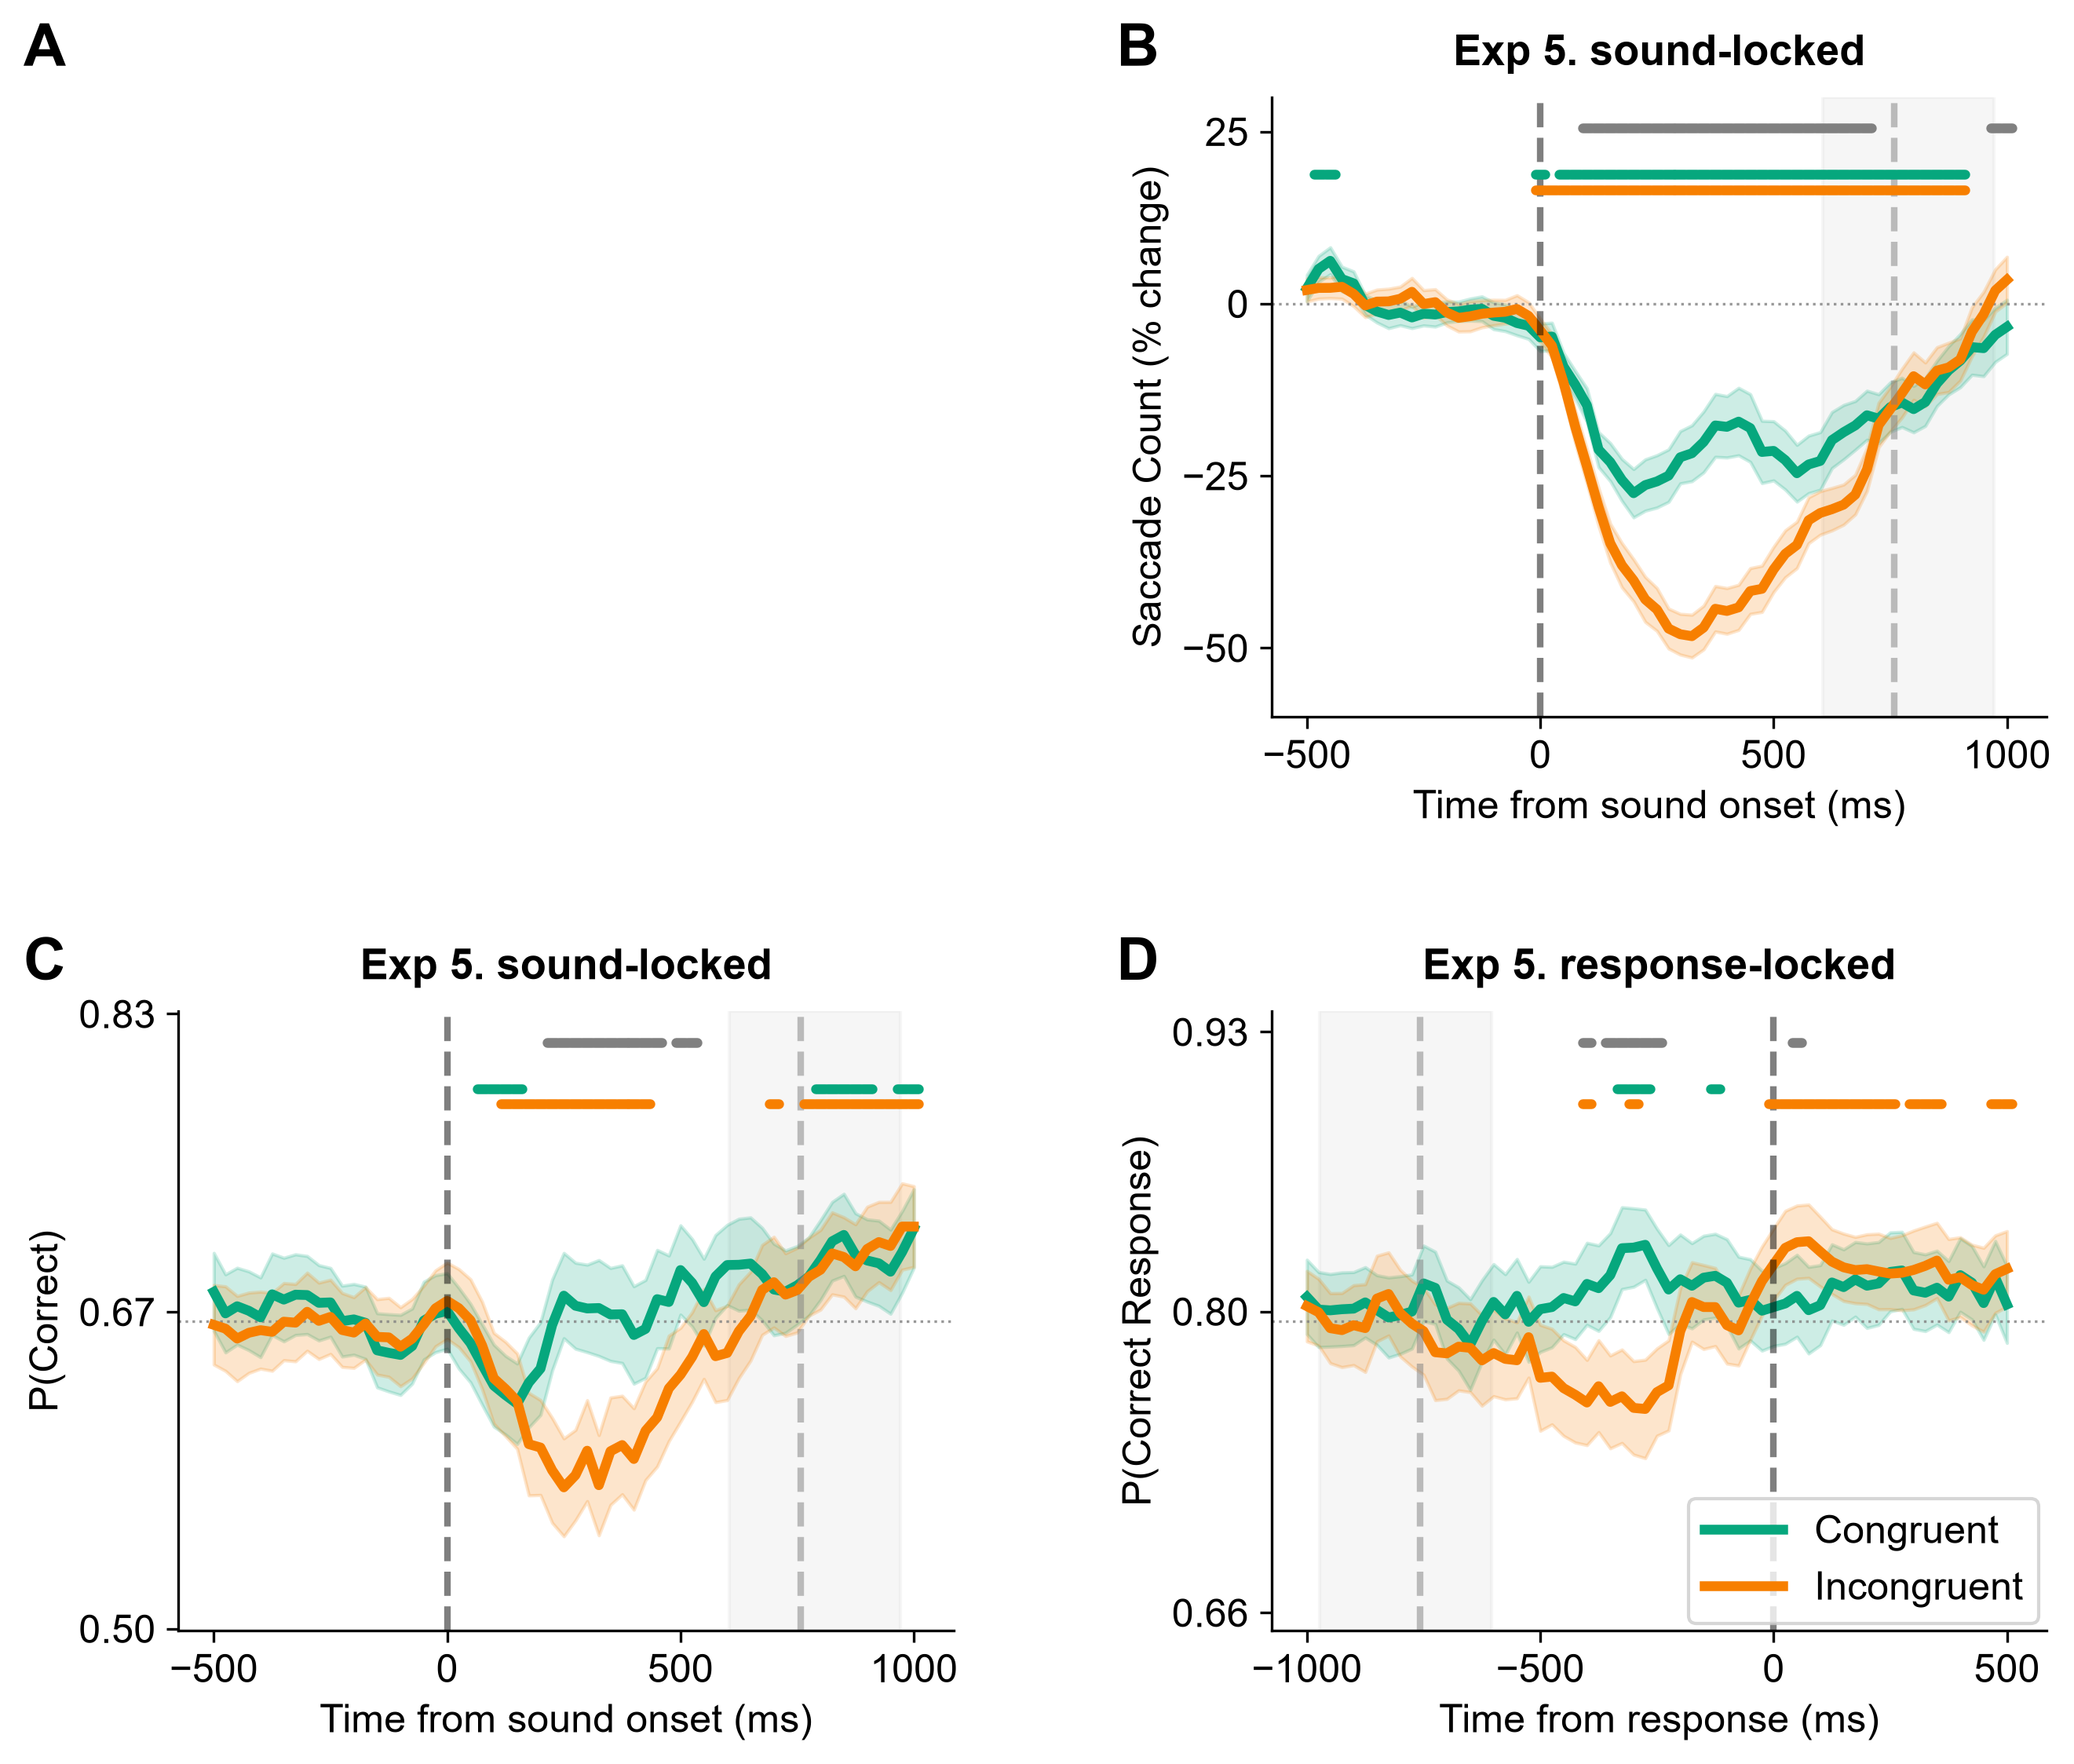

Saved summaries\plots\figure5.png (+ .pdf)  (8.81 in wide = 61.1% of Figure 2's width -> insert at that fraction of Figure 2's printed width)


In [7]:
fig, axes = line_grid(2, 2)
empty_axes(axes[0][0], 'A')
draw_line(axes[0][1], 'sound',    'count', title=panel_title('sound'),    panel_label='B')
draw_line(axes[1][0], 'sound',    'acc',   title=panel_title('sound'),    panel_label='C')
draw_line(axes[1][1], 'response', 'acc',   title=panel_title('response'), panel_label='D',
          legend=True, ylabel=YLABEL_D)
save(fig, 'figure5')

## Reported values

The statistics behind Figure 5, as the manuscript quotes them (`src/stats_report.py`):
FDR-significant windows grouped into intervals (window centres), with direction and mean size.
**Only windows before the response are reported** — sound-locked up to the median RT,
response-locked up to the response — each window ending by then (centre ≤ RT − half a window).
The FDR correction is the figure's (whole time range), so p values match the significance bars.

"Above / below baseline" for P(correct) is measured against each participant's own pre-sound value
per condition — exactly what the vs-baseline test compares with. Those values need the raw table,
so they are cached in `summaries/cache/figure5_report_baselines.pkl` (keyed like the curves).

In [8]:
import stats_report as sr
importlib.reload(sr)

BASELINE_CACHE = CACHE_DIR / 'figure5_report_baselines.pkl'
_bl = {}
if BASELINE_CACHE.exists():
    with open(BASELINE_CACHE, 'rb') as _f:
        _bl = pickle.load(_f)
_new = False
for alignment in ALIGNMENTS:
    key = (alignment, curve_key())
    if key not in _bl:
        data, filt = table()
        _bl[key] = sr.subject_baselines(data, filt[alignment]['filters'],
                                        ALIGNMENTS[alignment]['acc_metric'],
                                        BASELINE_RANGE, BASELINE_REFERENCE)
        _new = True
if _new:
    with open(BASELINE_CACHE, 'wb') as _f:
        pickle.dump(_bl, _f)

report_tables = []
median_rt = curves['rt'][0]
for alignment, spec in ALIGNMENTS.items():
    end = (median_rt if alignment == 'sound' else 0) - WINDOW_SIZE / 2
    rng = (0 if alignment == 'sound' else spec['time_range'][0], end)
    for kind, name in (('count', 'saccade count'), ('acc', 'P(correct)')):
        metric = spec[f'{kind}_metric']
        report_tables.append(sr.report(
            cache['sig'][(alignment, metric)], metric, curves['aligned'][alignment],
            f'{panel_title(alignment)} - {name}',
            baselines=None if kind == 'count' else _bl[(alignment, curve_key())],
            step=STEP_SIZE, report_range=rng, extremes=(('min', rng), ('max', rng))))
print(f"\nmedian RT: {median_rt:.0f} ms")


Exp 5. sound-locked - saccade count   [saccade_count_normalized, n = 53]
  congruent vs baseline             0–700 ms  below baseline      mean Δ  -19.9 pp   FDR p < 0.001 to 0.030
  incongruent vs baseline           0–700 ms  below baseline      mean Δ  -33.9 pp   FDR p < 0.001 to 0.043
  congruent vs incongruent        100–700 ms  congruent higher    mean Δ  +16.4 pp   FDR p < 0.001 to 0.027
  congruent   min in 0–708 ms:  t = 200 ms,  -27.5 %
  incongruent min in 0–708 ms:  t = 325 ms,  -48.3 %
  congruent   max in 0–708 ms:  t = 25 ms,  -4.8 %
  incongruent max in 0–708 ms:  t = 0 ms,  -3.9 %

Exp 5. sound-locked - P(correct)   [p_correct_response, n = 53]
  pre-sound level:  congruent 0.669,  incongruent 0.662
  congruent vs baseline            75–150 ms  below baseline      mean Δ    -0.039   FDR p 0.001 to 0.047
  incongruent vs baseline         125–425 ms  below baseline      mean Δ    -0.066   FDR p < 0.001 to 0.022
  incongruent vs baseline             700 ms  above baseline